In [1]:
# Imports 
import os, math, random, warnings
from pathlib import Path
import kagglehub

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2

warnings.filterwarnings('ignore')

# Reproducibility 
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_everything()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | Device: {DEVICE}')

PyTorch 2.10.0+cpu | Device: cpu


In [2]:

path = kagglehub.competition_download('multimodal-cancer-classification-challenge-2026')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/multimodal-cancer-classification-challenge-2026


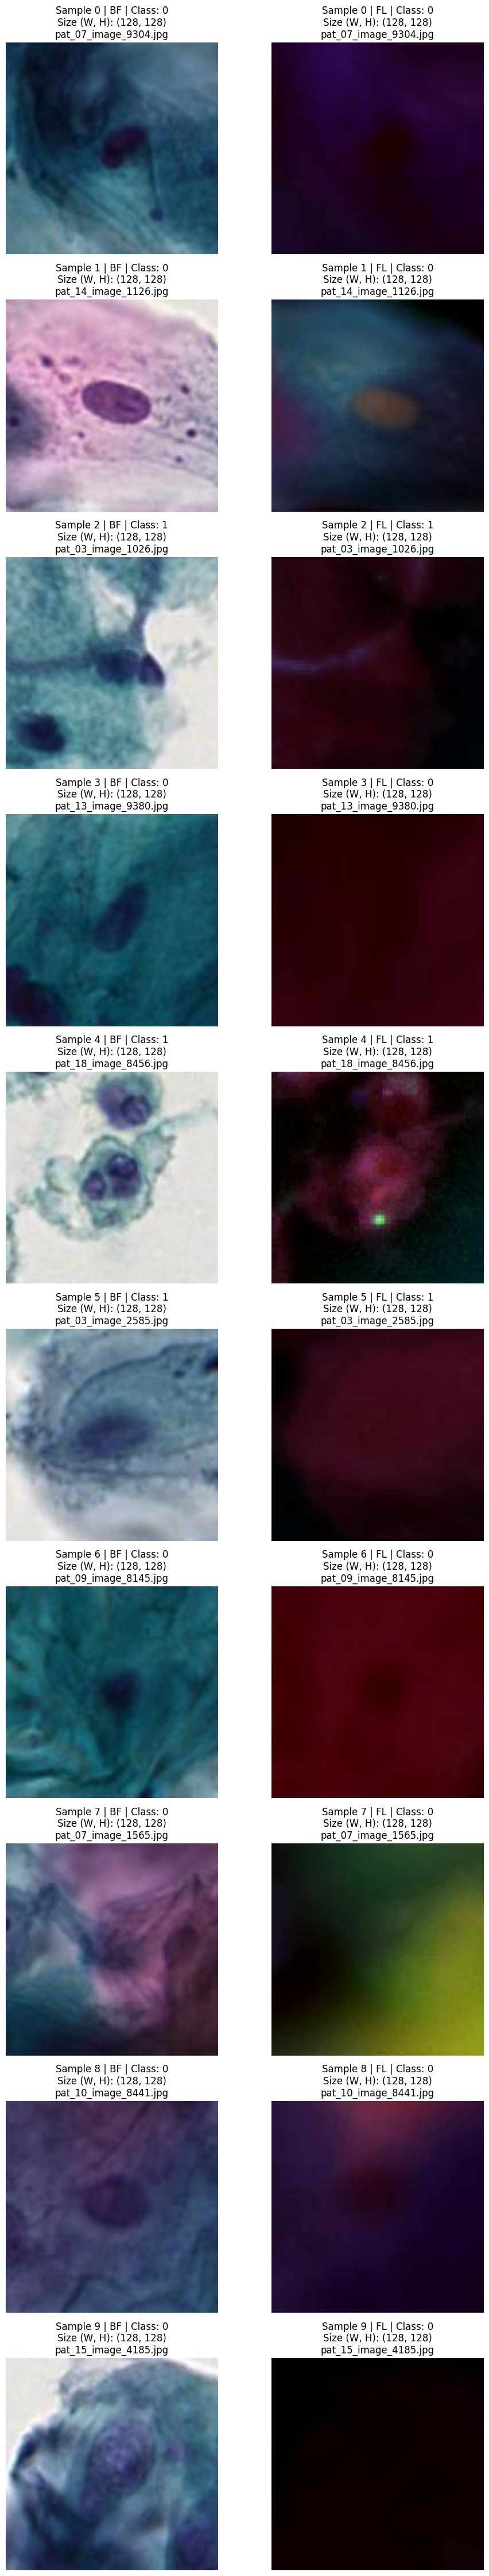

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image


INPUT_DIR = "/kaggle/input/competitions/multimodal-cancer-classification-challenge-2026"

# Load the csv
df_train = pd.read_csv(os.path.join(INPUT_DIR, 'train.csv'))


def plot_multimodal_samples(df, base_path, num_samples=10):
   
    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4.5 * num_samples))
    samples = df.sample(num_samples, random_state=42).reset_index(drop=True)
    
    for i, row in samples.iterrows():
        img_name = row['Name']
        label = row['Diagnosis']
        bf_path = os.path.join(base_path, 'BF', 'train', img_name)
        fl_path = os.path.join(base_path, 'FL', 'train', img_name)

        if os.path.exists(bf_path):
            img_bf = Image.open(bf_path)
            bf_size = img_bf.size # Extracts (width, height)
            
            axes[i, 0].imshow(img_bf, cmap='gray' if img_bf.mode == 'L' else None)
            axes[i, 0].set_title(f"Sample {i} | BF | Class: {label}\nSize (W, H): {bf_size}\n{img_name}")
            axes[i, 0].axis('off')
        else:
            axes[i, 0].text(0.5, 0.5, f"BF File Not Found:\n{bf_path}", ha='center', va='center', color='red')
            axes[i, 0].axis('off')

        if os.path.exists(fl_path):
            img_fl = Image.open(fl_path)
            fl_size = img_fl.size # Extracts (width, height)
            
            axes[i, 1].imshow(img_fl, cmap='gray' if img_fl.mode == 'L' else None)
            axes[i, 1].set_title(f"Sample {i} | FL | Class: {label}\nSize (W, H): {fl_size}\n{img_name}")
            axes[i, 1].axis('off')
        else:
            axes[i, 1].text(0.5, 0.5, f"FL File Not Found:\n{fl_path}", ha='center', va='center', color='red')
            axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()
plot_multimodal_samples(df_train, INPUT_DIR, num_samples=10)

In [4]:


INPUT_DIR = "/kaggle/input/competitions/multimodal-cancer-classification-challenge-2026"
df_train = pd.read_csv(os.path.join(INPUT_DIR, 'train.csv'))

df_train['Patient_ID'] = df_train['Name'].apply(lambda x: "_".join(x.split('_')[:2]))

print("=== DATASET PROFILE AUDIT ===")
print(f"Total individual cell images : {df_train.shape[0]}")
print(f"Total unique patient sources : {df_train['Patient_ID'].nunique()}")
print(f"Average cells per patient    : {df_train.shape[0] / df_train['Patient_ID'].nunique():.1f}")

print("\n=== CLASS DISTRIBUTION (DIAGNOSIS) ===")
print(df_train['Diagnosis'].value_counts())
print("\nIn percentages:")
print(df_train['Diagnosis'].value_counts(normalize=True) * 100)

print("\n=== TOP 5 PATIENTS BY CELL COUNT ===")
print(df_train['Patient_ID'].value_counts().head(5))

=== DATASET PROFILE AUDIT ===
Total individual cell images : 114302
Total unique patient sources : 12
Average cells per patient    : 9525.2

=== CLASS DISTRIBUTION (DIAGNOSIS) ===
Diagnosis
0    70000
1    44302
Name: count, dtype: int64

In percentages:
Diagnosis
0    61.241273
1    38.758727
Name: proportion, dtype: float64

=== TOP 5 PATIENTS BY CELL COUNT ===
Patient_ID
pat_03    10000
pat_07    10000
pat_09    10000
pat_10    10000
pat_15    10000
Name: count, dtype: int64


In [5]:
# ── Cell 2: Paths & Config ────────────────────────────────────────────────────
INPUT_DIR = Path('/kaggle/input/competitions/multimodal-cancer-classification-challenge-2026')
OUTPUT_DIR = Path('/kaggle/working')
OUTPUT_DIR.mkdir(exist_ok=True)

CFG = dict(
    img_size      = 224,
    batch_size    = 64,       # per-cell batch; reduce to 32 if OOM
    num_epochs    = 20,
    lr            = 3e-4,
    weight_decay  = 1e-4,
    n_folds       = 4,
    # MIL bag settings
    bag_size      = 32,       # cells sampled per patient per iteration
    # Focal loss
    focal_alpha   = 0.75,
    focal_gamma   = 2.0,
    # AMP
    use_amp       = True,
    # TTA at inference
    tta_n         = 5,
)

print('Config loaded.')
print(CFG)

Config loaded.
{'img_size': 224, 'batch_size': 64, 'num_epochs': 20, 'lr': 0.0003, 'weight_decay': 0.0001, 'n_folds': 4, 'bag_size': 32, 'focal_alpha': 0.75, 'focal_gamma': 2.0, 'use_amp': True, 'tta_n': 5}


In [6]:

df = pd.read_csv(INPUT_DIR / 'train.csv')
df['Patient_ID'] = df['Name'].apply(lambda x: '_'.join(x.split('_')[:2]))
df['bf_path'] = df['Name'].apply(lambda x: str(INPUT_DIR / 'BF' / 'train' / x))
df['fl_path'] = df['Name'].apply(lambda x: str(INPUT_DIR / 'FL' / 'train' / x))

print(df.shape)
print(df['Diagnosis'].value_counts())
print(df['Patient_ID'].value_counts())

(114302, 5)
Diagnosis
0    70000
1    44302
Name: count, dtype: int64
Patient_ID
pat_03    10000
pat_07    10000
pat_09    10000
pat_10    10000
pat_15    10000
pat_11    10000
pat_13    10000
pat_14    10000
pat_17    10000
pat_16    10000
pat_18    10000
pat_05     4302
Name: count, dtype: int64


In [7]:
# Albumentations augmentation pipelines 
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_aug = A.Compose([
    A.RandomResizedCrop(size=(CFG['img_size'], CFG['img_size']), scale=(0.7, 1.0)),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=30, p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, fill_value=0, p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_aug = A.Compose([
    A.Resize(height=CFG['img_size'], width=CFG['img_size']),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

print('Augmentations ready.')

Augmentations ready.


In [8]:
# Cell 5: Dataset — dual-channel (BF + FL stacked as 6 channels) 
#
# Strategy: load BF (RGB=3ch) and FL (RGB=3ch) → concatenate → 6-channel tensor.
# Each modality stream in the network sees its own 3 channels (split inside model).
# This is equivalent to "early feature extraction, late fusion".

class CancerCellDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Load BF
        try:
            img_bf = np.array(Image.open(row['bf_path']).convert('RGB'))
        except Exception:
            img_bf = np.zeros((CFG['img_size'], CFG['img_size'], 3), dtype=np.uint8)

        # Load FL
        try:
            img_fl = np.array(Image.open(row['fl_path']).convert('RGB'))
        except Exception:
            img_fl = np.zeros((CFG['img_size'], CFG['img_size'], 3), dtype=np.uint8)

        if self.transform:
            
            replay_data = self.transform(image=img_bf)
            img_bf_t    = replay_data['image']   # 3 x H x W

            img_fl_t = self.transform(image=img_fl)['image']  # 3 x H x W
        else:
            # Minimal fallback
             to_tensor = A.Compose([
                A.Resize(height=CFG['img_size'], width=CFG['img_size']),
                A.Normalize(mean=MEAN, std=STD),
                ToTensorV2()
                ])

        # 6-channel stacked tensor
        img = torch.cat([img_bf_t, img_fl_t], dim=0)   # (6, H, W)
        label = torch.tensor(row['Diagnosis'], dtype=torch.float32)
        return img, label

print('Dataset class defined.')

Dataset class defined.


In [9]:
# Cell 6: ResNet-14 (lightweight, custom)
#
# Architecture: 4 stages × 2 blocks + global avg pool + head
# Input: 6-channel (BF+FL), split inside the model for dual-stream processing
#
# Dual-stream intermediate fusion:
#   - BF stream:  3ch → stage1 → stage2
#   - FL stream:  3ch → stage1 → stage2
#   - Fuse (concat + 1×1 conv) after stage 2
#   - Shared stage3 → stage4 → attention pool → classifier

class BasicBlock(nn.Module):
    """Standard 2-conv residual block."""
    expansion = 1

    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch,  out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1,      padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)

        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample:
            identity = self.downsample(x)
        return F.relu(out + identity)


def _make_layer(in_ch, out_ch, num_blocks, stride=1):
    layers = [BasicBlock(in_ch, out_ch, stride=stride)]
    for _ in range(1, num_blocks):
        layers.append(BasicBlock(out_ch, out_ch))
    return nn.Sequential(*layers)


class DualStreamResNet14(nn.Module):
    """
    ResNet-14 with dual-stream intermediate fusion.
    Each stream handles one imaging modality (BF or FL, each 3ch).
    Fusion happens after stage-2 via concat + 1×1 projection.
    """
    def __init__(self, num_classes=1, base_ch=64):
        super().__init__()
        
        self.bf_stem   = nn.Sequential(
            nn.Conv2d(3, base_ch, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(base_ch), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1)
        )
        self.bf_stage1 = _make_layer(base_ch,      base_ch,      2, stride=1)
        self.bf_stage2 = _make_layer(base_ch,      base_ch * 2,  2, stride=2)

        
        self.fl_stem   = nn.Sequential(
            nn.Conv2d(3, base_ch, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(base_ch), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1)
        )
        self.fl_stage1 = _make_layer(base_ch,      base_ch,      2, stride=1)
        self.fl_stage2 = _make_layer(base_ch,      base_ch * 2,  2, stride=2)

        
        self.fusion = nn.Sequential(
            nn.Conv2d(base_ch * 4, base_ch * 2, 1, bias=False),
            nn.BatchNorm2d(base_ch * 2),
            nn.ReLU(inplace=True)
        )

        
        self.stage3    = _make_layer(base_ch * 2,  base_ch * 4,  2, stride=2)
        self.stage4    = _make_layer(base_ch * 4,  base_ch * 8,  2, stride=2)

        self.gap = nn.AdaptiveAvgPool2d(1)

       
        self.head = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(base_ch * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        """
        x: (B, 6, H, W)  — first 3ch = BF, last 3ch = FL
        """
        bf = x[:, :3, :, :]   # BF
        fl = x[:, 3:, :, :]   # FL

        # BF stream
        bf = self.bf_stage2(self.bf_stage1(self.bf_stem(bf)))

        # FL stream
        fl = self.fl_stage2(self.fl_stage1(self.fl_stem(fl)))

        # Fuse
        fused = self.fusion(torch.cat([bf, fl], dim=1))

        # Shared path
        out = self.stage4(self.stage3(fused))
        out = self.gap(out).flatten(1)
        return self.head(out)   # logits, shape (B, 1)


# Quick sanity check
_m = DualStreamResNet14().to(DEVICE)
_x = torch.randn(2, 6, 224, 224).to(DEVICE)
with torch.no_grad():
    _out = _m(_x)
print(f'Model output shape: {_out.shape}')   # should be (2, 1)
total_params = sum(p.numel() for p in _m.parameters())
print(f'Total parameters: {total_params:,}   (~{total_params/1e6:.1f}M)')
del _m, _x, _out

Model output shape: torch.Size([2, 1])
Total parameters: 12,024,193   (~12.0M)


In [10]:
# Cell 7: Focal Loss 

class FocalLoss(nn.Module):
    """
    Binary focal loss.
    alpha: weight for positive class (set > 0.5 when positives are minority)
    gamma: focusing parameter (2.0 is classic)
    """
    def __init__(self, alpha=0.75, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha     = alpha
        self.gamma     = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        """logits: (B,1) or (B,), targets: (B,) float"""
        logits  = logits.view(-1)
        targets = targets.view(-1)
        bce     = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs   = torch.sigmoid(logits)
        pt      = targets * probs + (1 - targets) * (1 - probs)
        alpha_t = targets * self.alpha + (1 - targets) * (1 - self.alpha)
        loss    = alpha_t * (1 - pt) ** self.gamma * bce
        if self.reduction == 'mean':
            return loss.mean()
        return loss.sum()

print('FocalLoss defined.')

FocalLoss defined.


In [11]:
#  Cell 8: Mixup augmentation 

def mixup_data(x, y, alpha=0.4):
    """Returns mixed inputs, pairs of targets, and lambda."""
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

print('Mixup helpers defined.')

Mixup helpers defined.


In [12]:
#  Cell 9: Training & validation loops 

def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()
    total_loss = 0.0
    all_labels, all_preds = [], []

    for imgs, labels in tqdm(loader, leave=False, desc='  train'):
        imgs, labels = imgs.to(device), labels.to(device)

        # Mixup
        imgs, la, lb, lam = mixup_data(imgs, labels, alpha=0.4)

        optimizer.zero_grad()
        with autocast(enabled=CFG['use_amp']):
            logits = model(imgs).squeeze(1)     # (B,)
            loss   = mixup_criterion(criterion, logits, la, lb, lam)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * imgs.size(0)
        all_labels.extend(la.cpu().numpy())
        all_preds.extend(torch.sigmoid(logits).detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    auc = roc_auc_score(all_labels, all_preds)
    return avg_loss, auc


@torch.no_grad()
def validate(model, loader, criterion, device, tta=False):
    model.eval()
    total_loss = 0.0
    all_labels, all_preds = [], []

    for imgs, labels in tqdm(loader, leave=False, desc='  val  '):
        imgs, labels = imgs.to(device), labels.to(device)

        if tta:
            # Average over N random augmented versions
            preds_tta = []
            for _ in range(CFG['tta_n']):
                with autocast(enabled=CFG['use_amp']):
                    logits = model(imgs).squeeze(1)
                preds_tta.append(torch.sigmoid(logits))
            logits_avg = torch.stack(preds_tta, 0).mean(0)  # average probs
            preds_out  = logits_avg
            loss_val   = criterion(torch.logit(logits_avg + 1e-6), labels)
        else:
            with autocast(enabled=CFG['use_amp']):
                logits = model(imgs).squeeze(1)
            loss_val   = criterion(logits, labels)
            preds_out  = torch.sigmoid(logits)

        total_loss += loss_val.item() * imgs.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds_out.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    auc = roc_auc_score(all_labels, all_preds)
    return avg_loss, auc


print('Train / validate loops defined.')

Train / validate loops defined.


In [13]:
# Cell 10: 4-Fold Manual Stratified Training
#
# WHY MANUAL FOLDS:
# With only 12 patients, StratifiedGroupKFold cannot guarantee both classes
# appear in every val set when multiple pure single-class patients exist.
# Manual round-robin assignment at the patient level is the only reliable fix.

patient_profile = df.groupby('Patient_ID').agg(
    total_cells    = ('Diagnosis', 'count'),
    malignant      = ('Diagnosis', 'sum'),
    benign         = ('Diagnosis', lambda x: (x == 0).sum()),
    unique_classes = ('Diagnosis', 'nunique')
).reset_index()

patient_profile['pct_malignant'] = (
    patient_profile['malignant'] / patient_profile['total_cells'] * 100
).round(1)

# Majority class label per patient (1 if >50% cells are malignant, else 0)
patient_profile['pat_label'] = (
    patient_profile['malignant'] / patient_profile['total_cells'] > 0.5
).astype(int)

print("=== Patient-Level Class Profile ===")
print(patient_profile[['Patient_ID', 'total_cells', 'malignant',
                        'benign', 'pct_malignant', 'unique_classes',
                        'pat_label']].to_string(index=False))

single_class = patient_profile[patient_profile['unique_classes'] == 1]
if len(single_class):
    print(f"\n⚠  Pure single-class patients detected: "
          f"{single_class['Patient_ID'].tolist()}")
else:
    print("\n✓  All patients have mixed-class cells.")


malignant_pats = patient_profile[
    patient_profile['pat_label'] == 1]['Patient_ID'].tolist()
benign_pats    = patient_profile[
    patient_profile['pat_label'] == 0]['Patient_ID'].tolist()

print(f"\nMalignant-majority patients ({len(malignant_pats)}): {malignant_pats}")
print(f"Benign-majority    patients ({len(benign_pats)}):    {benign_pats}")


random.seed(SEED)
random.shuffle(malignant_pats)
random.shuffle(benign_pats)

N_FOLDS = 4
folds   = []

for i in range(N_FOLDS):
    
    val_mal      = malignant_pats[i::N_FOLDS]
    val_ben      = benign_pats[i::N_FOLDS]
    val_patients = val_mal + val_ben
    tr_patients  = [p for p in patient_profile['Patient_ID'].tolist()
                    if p not in val_patients]
    folds.append((tr_patients, val_patients))

print("\n=== Fold Assignment Verification ===")
for i, (tr_pats, vl_pats) in enumerate(folds):
    vl_df     = df[df['Patient_ID'].isin(vl_pats)]
    tr_df     = df[df['Patient_ID'].isin(tr_pats)]
    vl_labels = vl_df['Diagnosis'].unique().tolist()
    overlap   = set(tr_pats) & set(vl_pats)   # must be empty
    print(f"Fold {i+1}:  "
          f"train_patients={tr_pats}  "
          f"val_patients={vl_pats}  "
          f"val_classes={sorted(vl_labels)}  "
          f"leakage={len(overlap) > 0}  "
          f"train_cells={len(tr_df):,}  "
          f"val_cells={len(vl_df):,}")
    assert len(overlap) == 0,   f"LEAKAGE in fold {i+1}!"
    assert len(vl_labels) == 2, f"Single-class val in fold {i+1}!"

print("\n✓  All folds passed: no leakage, both classes in every val set.")

best_fold_aucs = []
oof_preds      = np.zeros(len(df))

for fold, (tr_patients, vl_patients) in enumerate(folds):

    print(f"\n{'='*60}")
    print(f"  FOLD {fold+1}/{N_FOLDS}"
          f"  |  Train patients: {tr_patients}"
          f"  |  Val patients:   {vl_patients}")
    print(f"{'='*60}")

    df_train_fold = df[df['Patient_ID'].isin(tr_patients)].reset_index(drop=True)
    df_val_fold   = df[df['Patient_ID'].isin(vl_patients)].reset_index(drop=True)

    train_ds = CancerCellDataset(df_train_fold, transform=train_aug)
    val_ds   = CancerCellDataset(df_val_fold,   transform=val_aug)

    class_counts   = df_train_fold['Diagnosis'].value_counts().sort_index().values
    class_weights  = 1.0 / class_counts.astype(float)
    sample_weights = class_weights[df_train_fold['Diagnosis'].values]
    sampler = WeightedRandomSampler(
        weights     = torch.from_numpy(sample_weights).float(),
        num_samples = len(train_ds),
        replacement = True
    )

    train_loader = DataLoader(
        train_ds,
        batch_size  = CFG['batch_size'],
        sampler     = sampler,
        num_workers = 4,
        pin_memory  = True
    )
    val_loader = DataLoader(
        val_ds,
        batch_size  = CFG['batch_size'] * 2,
        shuffle     = False,
        num_workers = 4,
        pin_memory  = True
    )

    model     = DualStreamResNet14(num_classes=1).to(DEVICE)
    criterion = FocalLoss(alpha=CFG['focal_alpha'], gamma=CFG['focal_gamma'])
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr           = CFG['lr'],
        weight_decay = CFG['weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=CFG['num_epochs'], eta_min=1e-6
    )
    scaler = GradScaler(enabled=CFG['use_amp'])

    best_val_auc   = 0.0
    best_ckpt_path = OUTPUT_DIR / f'best_fold{fold+1}.pt'

    for epoch in range(CFG['num_epochs']):
        tr_loss, tr_auc = train_one_epoch(
            model, train_loader, optimizer, criterion, scaler, DEVICE
        )
        vl_loss, vl_auc = validate(
            model, val_loader, criterion, DEVICE, tta=False
        )
        scheduler.step()

        print(f"  Ep {epoch+1:02d}/{CFG['num_epochs']}  "
              f"tr_loss={tr_loss:.4f}  tr_auc={tr_auc:.4f}  "
              f"vl_loss={vl_loss:.4f}  vl_auc={vl_auc:.4f}  "
              f"lr={scheduler.get_last_lr()[0]:.2e}")

        if vl_auc > best_val_auc:
            best_val_auc = vl_auc
            torch.save(model.state_dict(), best_ckpt_path)
            print(f"    ✓ Saved best model  (val_auc={best_val_auc:.4f})")

    print(f"\n  Loading best checkpoint for fold {fold+1}...")
    model.load_state_dict(torch.load(best_ckpt_path, map_location=DEVICE))
    model.eval()

    probs_list = []
    with torch.no_grad():
        for imgs, _ in tqdm(val_loader, leave=False, desc=f"  OOF TTA fold{fold+1}"):
            imgs       = imgs.to(DEVICE)
            tta_ps     = [
                torch.sigmoid(model(imgs).squeeze(1))
                for _ in range(CFG['tta_n'])
            ]
            batch_probs = torch.stack(tta_ps, dim=0).mean(dim=0)
            probs_list.extend(batch_probs.cpu().numpy())

    val_global_idx            = df[df['Patient_ID'].isin(vl_patients)].index.values
    oof_preds[val_global_idx] = probs_list

    oof_auc = roc_auc_score(df_val_fold['Diagnosis'].values, probs_list)
    best_fold_aucs.append(oof_auc)
    print(f"  Fold {fold+1} OOF AUC (TTA): {oof_auc:.4f}")

print(f"\n{'='*60}")
print(f"CV AUC per fold : {[f'{a:.4f}' for a in best_fold_aucs]}")
print(f"Mean CV AUC     : {np.mean(best_fold_aucs):.4f} "
      f"± {np.std(best_fold_aucs):.4f}")
print(f"Overall OOF AUC : {roc_auc_score(df['Diagnosis'].values, oof_preds):.4f}")

=== Patient-Level Class Profile ===
Patient_ID  total_cells  malignant  benign  pct_malignant  unique_classes  pat_label
    pat_03        10000      10000       0          100.0               1          1
    pat_05         4302       4302       0          100.0               1          1
    pat_07        10000          0   10000            0.0               1          0
    pat_09        10000          0   10000            0.0               1          0
    pat_10        10000          0   10000            0.0               1          0
    pat_11        10000          0   10000            0.0               1          0
    pat_13        10000          0   10000            0.0               1          0
    pat_14        10000          0   10000            0.0               1          0
    pat_15        10000          0   10000            0.0               1          0
    pat_16        10000      10000       0          100.0               1          1
    pat_17        10000      

  train:   0%|          | 0/1161 [00:00<?, ?it/s]

  val  :   0%|          | 0/313 [00:00<?, ?it/s]

  Ep 01/20  tr_loss=0.0492  tr_auc=0.7231  vl_loss=0.0869  vl_auc=0.8005  lr=2.98e-04
    ✓ Saved best model  (val_auc=0.8005)


  train:   0%|          | 0/1161 [00:00<?, ?it/s]

...

  train:   0%|          | 0/1474 [00:00<?, ?it/s]

  val  :   0%|          | 0/157 [00:00<?, ?it/s]

  Ep 20/20  tr_loss=0.0380  tr_auc=0.7592  vl_loss=0.0464  vl_auc=0.9818  lr=1.00e-06

  Loading best checkpoint for fold 4...


  OOF TTA fold4:   0%|          | 0/157 [00:00<?, ?it/s]

  Fold 4 OOF AUC (TTA): 0.9890

CV AUC per fold : ['0.8885', '0.9053', '0.9130', '0.9890']
Mean CV AUC     : 0.9239 ± 0.0386
Overall OOF AUC : 0.9080


In [14]:
#  Cell 11: Test Inference — 4-fold ensemble with TTA

import shutil

# Step 1: Build test dataframe
bf_test_dir = INPUT_DIR / 'BF' / 'test'

test_files = sorted(bf_test_dir.glob('*.png'))
if not test_files:
    test_files = sorted(bf_test_dir.glob('*.jpg'))
if not test_files:
    test_files = sorted(bf_test_dir.glob('*.*'))

assert len(test_files) > 0, f"No test files found in {bf_test_dir}"
print(f'Test files found: {len(test_files)}')
print(f'Example: {test_files[0].name}')

df_test = pd.DataFrame({
    'Name'      : [f.name for f in test_files],
    'bf_path'   : [str(INPUT_DIR / 'BF' / 'test' / f.name) for f in test_files],
    'fl_path'   : [str(INPUT_DIR / 'FL' / 'test' / f.name) for f in test_files],
    'Diagnosis' : 0   
})

print(f'Test dataframe shape: {df_test.shape}')

# Step 2: Dataset & loader 
test_ds = CancerCellDataset(df_test, transform=val_aug)
test_loader = DataLoader(
    test_ds,
    batch_size  = CFG['batch_size'] * 2,
    shuffle     = False,
    num_workers = 4,
    pin_memory  = True
)


N_FOLDS = 4 
missing = []
for fold in range(N_FOLDS):
    ckpt = OUTPUT_DIR / f'best_fold{fold+1}.pt'
    if not ckpt.exists():
        missing.append(str(ckpt))

if missing:
    raise FileNotFoundError(
        f"Missing checkpoints — did training complete?\n" +
        "\n".join(missing)
    )
print(f'✓ All {N_FOLDS} checkpoints found.')

# Ensemble inference — 4 folds × 5 TTA = 20 predictions per cell
fold_test_preds = []

for fold in range(N_FOLDS):
    ckpt_path = OUTPUT_DIR / f'best_fold{fold+1}.pt'
    model = DualStreamResNet14(num_classes=1).to(DEVICE)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    fold_probs = []
    with torch.no_grad():
        for imgs, _ in tqdm(test_loader, leave=False,
                            desc=f'  Fold {fold+1}/{N_FOLDS} TTA'):
            imgs    = imgs.to(DEVICE)
            tta_ps  = [
                torch.sigmoid(model(imgs).squeeze(1))
                for _ in range(CFG['tta_n'])
            ]
            batch_probs = torch.stack(tta_ps, dim=0).mean(dim=0)
            fold_probs.extend(batch_probs.cpu().numpy())

    fold_test_preds.append(fold_probs)
    print(f'  Fold {fold+1} done  |  '
          f'mean_pred={np.mean(fold_probs):.4f}  '
          f'samples={len(fold_probs)}')

    # Free GPU memory between folds
    del model
    torch.cuda.empty_cache()

# Step 5: Average across folds
ensemble_preds = np.mean(fold_test_preds, axis=0)

print(f'\nEnsemble stats:')
print(f'  Total predictions : {len(ensemble_preds)}')
print(f'  Mean probability  : {ensemble_preds.mean():.4f}')
print(f'  Std               : {ensemble_preds.std():.4f}')
print(f'  Min / Max         : {ensemble_preds.min():.4f} / {ensemble_preds.max():.4f}')

submission = pd.DataFrame({
    'Name'     : df_test['Name'].values,
    'Diagnosis': ensemble_preds
})

assert submission['Diagnosis'].isna().sum() == 0, "NaNs in predictions!"
assert len(submission) == len(df_test),            "Row count mismatch!"

print(f'\nSubmission shape: {submission.shape}')
print(submission.head(10))

primary_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(primary_path, index=False)
print(f'\n✓ Saved to primary:   {primary_path}')

import datetime
timestamp   = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
backup_name = f'submission_{timestamp}.csv'
backup_path = OUTPUT_DIR / backup_name
submission.to_csv(backup_path, index=False)
print(f'✓ Saved backup copy:  {backup_path}')

for p in [primary_path, backup_path]:
    size_kb = p.stat().st_size / 1024
    print(f'  {p.name}  →  {size_kb:.1f} KB  ✓')

print(f'\n=== All files in {OUTPUT_DIR} ===')
all_files = sorted(OUTPUT_DIR.iterdir())
for f in all_files:
    size_kb = f.stat().st_size / 1024
    print(f'  {f.name:<45}  {size_kb:>8.1f} KB')

Test files found: 59040
Example: image_1.jpg
Test dataframe shape: (59040, 4)
✓ All 4 checkpoints found.


  Fold 1/4 TTA:   0%|          | 0/462 [00:00<?, ?it/s]

  Fold 1 done  |  mean_pred=0.5793  samples=59040


  Fold 2/4 TTA:   0%|          | 0/462 [00:00<?, ?it/s]

  Fold 2 done  |  mean_pred=0.5464  samples=59040


  Fold 3/4 TTA:   0%|          | 0/462 [00:00<?, ?it/s]

  Fold 3 done  |  mean_pred=0.5774  samples=59040


  Fold 4/4 TTA:   0%|          | 0/462 [00:00<?, ?it/s]

  Fold 4 done  |  mean_pred=0.5324  samples=59040

Ensemble stats:
  Total predictions : 59040
  Mean probability  : 0.5589
  Std               : 0.1268
  Min / Max         : 0.2792 / 0.9059

Submission shape: (59040, 2)
              Name  Diagnosis
0      image_1.jpg   0.612052
1     image_10.jpg   0.683101
2    image_100.jpg   0.429241
3   image_1000.jpg   0.605626
4  image_10000.jpg   0.467809
5  image_10001.jpg   0.411127
6  image_10002.jpg   0.686763
7  image_10003.jpg   0.623844
8  image_10004.jpg   0.705219
9  image_10005.jpg   0.451677

✓ Saved to primary:   /kaggle/working/submission.csv
✓ Saved backup copy:  /kaggle/working/submission_20260602_032628.csv
  submission.csv  →  1514.7 KB  ✓
  submission_20260602_032628.csv  →  1514.7 KB  ✓

=== All files in /kaggle/working ===
  .virtual_documents                                  4.0 KB
  best_fold1.pt                                   47078.1 KB
  best_fold2.pt                                   47078.1 KB
  best_fold3.pt      

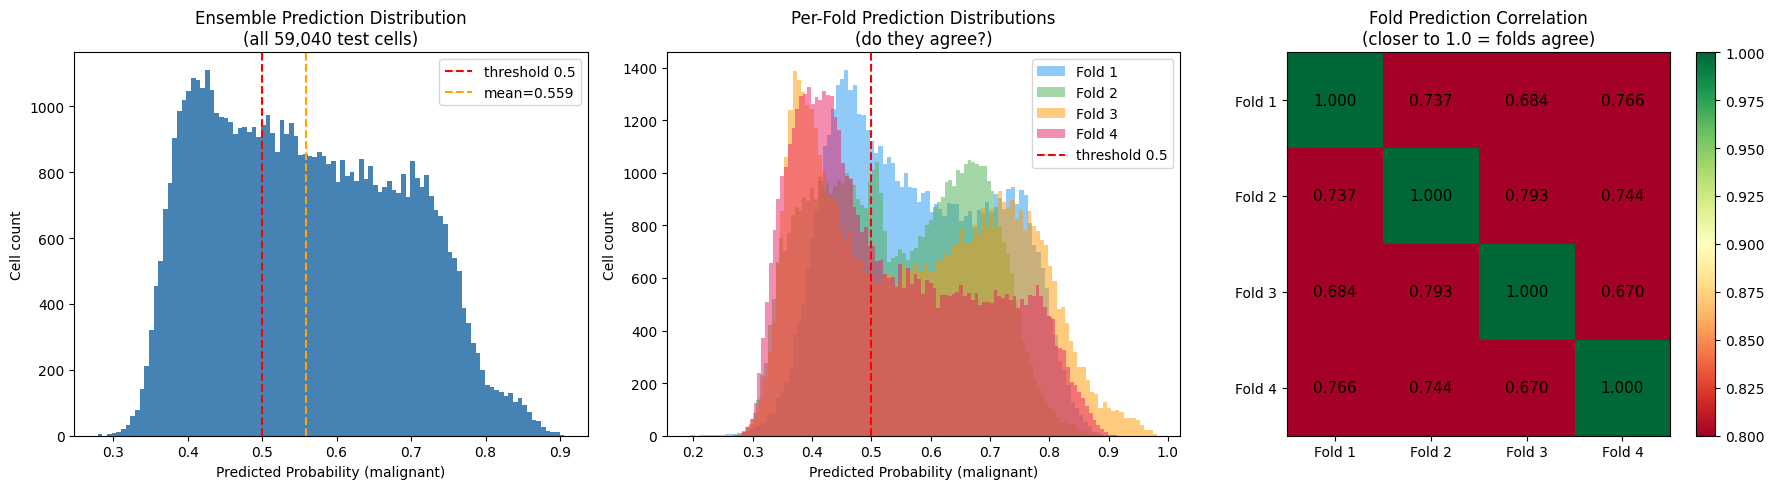

=== Ensemble Prediction Summary ===
Total test cells     : 59,040
Mean probability     : 0.5589
Std                  : 0.1268
Min / Max            : 0.2792 / 0.9059
Cells > 0.5 (pred M) : 36,708 (62.2%)
Cells < 0.5 (pred B) : 22,332 (37.8%)
Cells near 0.5 ±0.1  : 29,883   ← these are the uncertain/borderline cells

=== Per-Fold Mean Predictions ===
  Fold 1: mean=0.5793  std=0.1283  >0.5: 66.2%
  Fold 2: mean=0.5464  std=0.1284  >0.5: 59.3%
  Fold 3: mean=0.5774  std=0.1615  >0.5: 60.9%
  Fold 4: mean=0.5324  std=0.1497  >0.5: 48.9%


In [19]:
import matplotlib.pyplot as plt

fold_colors = ['#2196F3', '#4CAF50', '#FF9800', '#E91E63']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(ensemble_preds, bins=100, color='steelblue', edgecolor='none')
axes[0].axvline(0.5,  color='red',   linestyle='--', label='threshold 0.5')
axes[0].axvline(ensemble_preds.mean(), color='orange',
                linestyle='--', label=f'mean={ensemble_preds.mean():.3f}')
axes[0].set_title('Ensemble Prediction Distribution\n(all 59,040 test cells)')
axes[0].set_xlabel('Predicted Probability (malignant)')
axes[0].set_ylabel('Cell count')
axes[0].legend()

for i, fp in enumerate(fold_test_preds):
    axes[1].hist(fp, bins=100, alpha=0.5,
                 color=fold_colors[i], label=f'Fold {i+1}',
                 edgecolor='none')
axes[1].axvline(0.5, color='red', linestyle='--', label='threshold 0.5')
axes[1].set_title('Per-Fold Prediction Distributions\n(do they agree?)')
axes[1].set_xlabel('Predicted Probability (malignant)')
axes[1].set_ylabel('Cell count')
axes[1].legend()

import numpy as np
fold_array  = np.array(fold_test_preds)   # (4, 59040)
corr_matrix = np.corrcoef(fold_array)     # (4, 4)

im = axes[2].imshow(corr_matrix, cmap='RdYlGn', vmin=0.8, vmax=1.0)
axes[2].set_title('Fold Prediction Correlation\n(closer to 1.0 = folds agree)')
axes[2].set_xticks(range(N_FOLDS))
axes[2].set_yticks(range(N_FOLDS))
axes[2].set_xticklabels([f'Fold {i+1}' for i in range(N_FOLDS)])
axes[2].set_yticklabels([f'Fold {i+1}' for i in range(N_FOLDS)])
plt.colorbar(im, ax=axes[2])

for i in range(N_FOLDS):
    for j in range(N_FOLDS):
        axes[2].text(j, i, f'{corr_matrix[i,j]:.3f}',
                    ha='center', va='center', fontsize=11,
                    color='black')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'prediction_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('=== Ensemble Prediction Summary ===')
print(f'Total test cells     : {len(ensemble_preds):,}')
print(f'Mean probability     : {ensemble_preds.mean():.4f}')
print(f'Std                  : {ensemble_preds.std():.4f}')
print(f'Min / Max            : {ensemble_preds.min():.4f} / {ensemble_preds.max():.4f}')
print(f'Cells > 0.5 (pred M) : {(ensemble_preds > 0.5).sum():,} '
      f'({(ensemble_preds > 0.5).mean()*100:.1f}%)')
print(f'Cells < 0.5 (pred B) : {(ensemble_preds < 0.5).sum():,} '
      f'({(ensemble_preds < 0.5).mean()*100:.1f}%)')
print(f'Cells near 0.5 ±0.1  : {((ensemble_preds > 0.4) & (ensemble_preds < 0.6)).sum():,} '
      f'  ← these are the uncertain/borderline cells')

print('\n=== Per-Fold Mean Predictions ===')
for i, fp in enumerate(fold_test_preds):
    fp_arr = np.array(fp)
    print(f'  Fold {i+1}: mean={fp_arr.mean():.4f}  '
          f'std={fp_arr.std():.4f}  '
          f'>0.5: {(fp_arr > 0.5).mean()*100:.1f}%')

In [18]:

import zipfile, datetime, os

N_FOLDS   = 4
timestamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')


print('=== Checkpoint Verification ===')
total_size = 0
ckpt_paths = []

for fold in range(N_FOLDS):
    ckpt_path = OUTPUT_DIR / f'best_fold{fold+1}.pt'
    if not ckpt_path.exists():
        print(f'  ✗ MISSING: {ckpt_path.name}')
        continue
    size_mb = ckpt_path.stat().st_size / (1024 ** 2)
    total_size += size_mb
    ckpt_paths.append(ckpt_path)
    print(f'  ✓ {ckpt_path.name:<25}  {size_mb:.1f} MB')

print(f'\n  Total checkpoint size: {total_size:.1f} MB')
print(f'  Checkpoints found:     {len(ckpt_paths)}/{N_FOLDS}')


print('\n=== Saving enriched checkpoints ===')

for fold in range(N_FOLDS):
    ckpt_path = OUTPUT_DIR / f'best_fold{fold+1}.pt'
    if not ckpt_path.exists():
        continue

    state_dict = torch.load(ckpt_path, map_location='cpu')
    save_bundle = {
        'fold'         : fold + 1,
        'n_folds'      : N_FOLDS,
        'model_name'   : 'DualStreamResNet14',
        'num_classes'  : 1,
        'img_size'     : CFG['img_size'],
        'state_dict'   : state_dict,
        'cfg'          : CFG,
        'fold_auc'     : best_fold_aucs[fold] if fold < len(best_fold_aucs) else None,
        'timestamp'    : timestamp,
    }

    enriched_path = OUTPUT_DIR / f'model_fold{fold+1}_{timestamp}.pt'
    torch.save(save_bundle, enriched_path)
    size_mb = enriched_path.stat().st_size / (1024 ** 2)
    print(f'  ✓ Saved: {enriched_path.name}  ({size_mb:.1f} MB)')


print('\n=== Creating zip archive ===')

zip_path = OUTPUT_DIR / f'all_models_{timestamp}.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fold in range(N_FOLDS):
       
        enriched_path = OUTPUT_DIR / f'model_fold{fold+1}_{timestamp}.pt'
        if enriched_path.exists():
            zf.write(enriched_path, enriched_path.name)
    # Also add the submission csv
    sub_path = OUTPUT_DIR / 'submission.csv'
    if sub_path.exists():
        zf.write(sub_path, 'submission.csv')

zip_size_mb = zip_path.stat().st_size / (1024 ** 2)
print(f'  ✓ Zip created: {zip_path.name}  ({zip_size_mb:.1f} MB)')

print(f'\n=== All files in {OUTPUT_DIR} ===')
all_files = sorted(OUTPUT_DIR.iterdir())
for f in all_files:
    size_mb = f.stat().st_size / (1024 ** 2)
    print(f'  {f.name:<50}  {size_mb:>8.2f} MB')

print('\n✓ All done. Click Save Version in the top right to persist everything.')

=== Checkpoint Verification ===
  ✓ best_fold1.pt              46.0 MB
  ✓ best_fold2.pt              46.0 MB
  ✓ best_fold3.pt              46.0 MB
  ✓ best_fold4.pt              46.0 MB

  Total checkpoint size: 183.9 MB
  Checkpoints found:     4/4

=== Saving enriched checkpoints ===
  ✓ Saved: model_fold1_20260602_032648.pt  (46.0 MB)
  ✓ Saved: model_fold2_20260602_032648.pt  (46.0 MB)
  ✓ Saved: model_fold3_20260602_032648.pt  (46.0 MB)
  ✓ Saved: model_fold4_20260602_032648.pt  (46.0 MB)

=== Creating zip archive ===
  ✓ Zip created: all_models_20260602_032648.zip  (170.9 MB)

=== All files in /kaggle/working ===
  .virtual_documents                                      0.00 MB
  all_models_20260602_032628.zip                        170.93 MB
  all_models_20260602_032638.zip                        170.93 MB
  all_models_20260602_032648.zip                        170.93 MB
  best_fold1.pt                                          45.97 MB
  best_fold2.pt                          